# NOTEBOOK 1 – KHÁM PHÁ DỮ LIỆU (NV3)
**Đề tài:** Sử dụng thuật toán Naive Bayes để phân loại tin nhắn lừa đảo trực tuyến
**Dataset:** D1 – SMS Phishing Dataset for Machine Learning and Pattern Recognition (Mishra & Soni, Mendeley Data, CC BY 4.0)

## Notebook này làm gì?
| Bước | Việc cần làm | Yêu cầu NV3 |
|---|---|---|
| 1 | Đọc dataset gốc bằng Pandas | (1) |
| 2 | Đếm số dòng/cột, số mẫu từng nhãn | (2) |
| 3 | Tính tỷ lệ phần trăm từng nhãn | (3) |
| 4 | Kiểm tra dữ liệu thiếu, trùng, sai định dạng | (4) |
| 5 | Vẽ biểu đồ phân bố nhãn | (5) |
| 6 | Nhận xét dữ liệu cân bằng hay mất cân bằng | (6) |

## Cách chạy
1. Đặt file gốc vào `data/raw/Dataset_5971.csv` (đúng file đã tải ở Phần 2, **không chỉnh sửa**).
2. Mở notebook bằng Jupyter / VS Code / Google Colab, chọn **Run All**.
3. Kết quả tự lưu vào `outputs/tables/` (bảng) và `outputs/figures/` (biểu đồ).

> **Nguyên tắc:** notebook này **chỉ đọc**, không sửa, không ghi đè file gốc. Việc làm sạch nằm ở Notebook 2.

## Bước 0. Nhập thư viện và cấu hình đường dẫn
Giải thích: gom hết đường dẫn vào một chỗ để khi đổi máy chỉ cần sửa `DATA_PATH`.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ====== CẤU HÌNH (chỉ cần sửa ở đây) ======
DATA_PATH  = Path("data/raw/Dataset_5971.csv")   # file gốc
OUT_TABLES = Path("outputs/tables")              # nơi lưu bảng thống kê
OUT_FIGS   = Path("outputs/figures")             # nơi lưu biểu đồ
OUT_TABLES.mkdir(parents=True, exist_ok=True)
OUT_FIGS.mkdir(parents=True, exist_ok=True)

LABELS_OK = ["ham", "spam", "smishing"]          # 3 nhãn hợp lệ theo mô tả dataset
FLAG_COLS = ["URL", "EMAIL", "PHONE"]            # 3 cột cờ yes/No

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11
print("pandas", pd.__version__)

pandas 3.0.6


## Bước 1. Đọc dataset gốc bằng Pandas

Có 3 điểm cần chú ý khi đọc (đây là lý do code hơi khác `pd.read_csv` mặc định):

* `dtype=str`: đọc **mọi cột là chuỗi** để không bị Pandas tự đoán kiểu, tránh làm mất thông tin gốc.
* `keep_default_na=False`: mặc định Pandas biến các chuỗi như `"NA"`, `"None"`, `"null"` thành giá trị thiếu (NaN). Trong tin nhắn, đó có thể là chữ thật. Tắt đi để **không vô tình làm biến mất dữ liệu**. Ô rỗng sẽ được kiểm tra riêng ở Bước 4.
* Thử lần lượt các bảng mã (`utf-8` trước) vì mô tả dataset là UTF-8; nếu lỗi mới thử bảng mã khác.

In [2]:
def read_csv_safe(path):
    # Đọc CSV, thử lần lượt các encoding. Trả về (DataFrame, encoding đã dùng)
    last_err = None
    for enc in ["utf-8", "utf-8-sig", "cp1252", "latin-1"]:
        try:
            df = pd.read_csv(path, encoding=enc, dtype=str, keep_default_na=False)
            return df, enc
        except UnicodeDecodeError as e:
            last_err = e
    raise last_err

assert DATA_PATH.exists(), f"Không thấy file {DATA_PATH}. Hãy đặt Dataset_5971.csv vào data/raw/"

df_raw, used_encoding = read_csv_safe(DATA_PATH)
df_raw.columns = df_raw.columns.str.strip()      # bỏ khoảng trắng thừa ở tên cột (nếu có)
print("Encoding đọc được:", used_encoding)
df_raw.head(8)

Encoding đọc được: utf-8


,LABEL,TEXT,URL,EMAIL,PHONE
0,ham,Your opinion about me? 1. Over 2. Jada 3. Kusruthi 4. Lovable 5. Silent 6. Spl character 7. Not ...,No,No,No
1,ham,What's up? Do you want me to come online? If you are free we can talk sometime�,No,No,No
2,ham,So u workin overtime nigpun?,No,No,No
3,ham,"Also sir, i sent you an email about how to log into the usc payment portal. I.ll send you anothe...",No,No,No
4,Smishing,Please Stay At Home. To encourage the notion of staying at home. All tax-paying citizens are ent...,No,No,No
5,Smishing,BankOfAmerica Alert 137943. Please follow http://bit.do/cgjK-and re-activate,yes,No,yes
6,ham,Sorry dude. Dont know how i forgot. Even after Dan reminded me. Sorry. Hope you guys had fun.,No,No,No
7,ham,I don't quite know what to do. I still can't get hold of anyone. I cud pick you up bout 7.30pm a...,No,No,No


## Bước 2. Đếm số dòng/cột và số mẫu từng nhãn

In [3]:
n_rows, n_cols = df_raw.shape
print(f"Số dòng dữ liệu : {n_rows:,}  (không tính dòng tiêu đề)")
print(f"Số cột          : {n_cols}")
print("Tên cột         :", list(df_raw.columns))

expected_cols = {"LABEL", "TEXT", "URL", "EMAIL", "PHONE"}
assert expected_cols.issubset(df_raw.columns), f"Thiếu cột: {expected_cols - set(df_raw.columns)}"

df_raw.info()

Số dòng dữ liệu : 5,971  (không tính dòng tiêu đề)
Số cột          : 5
Tên cột         : ['LABEL', 'TEXT', 'URL', 'EMAIL', 'PHONE']
<class 'pandas.DataFrame'>
RangeIndex: 5971 entries, 0 to 5970
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   LABEL   5971 non-null   str  
 1   TEXT    5971 non-null   str  
 2   URL     5971 non-null   str  
 3   EMAIL   5971 non-null   str  
 4   PHONE   5971 non-null   str  
dtypes: str(5)
memory usage: 233.4 KB


### 2.1 Đếm nhãn **nguyên bản** (phân biệt hoa/thường)
Bước này để **thấy lỗi viết hoa/thường lẫn lộn** (ví dụ `spam` và `Spam` bị tính là 2 nhãn khác nhau).

In [4]:
label_raw_counts = df_raw["LABEL"].value_counts(dropna=False)
print(label_raw_counts)
print("\nSố giá trị nhãn khác nhau (chưa chuẩn hóa):", label_raw_counts.shape[0])

LABEL
ham         4844
Smishing     616
spam         466
Spam          23
smishing      22
Name: count, dtype: int64

Số giá trị nhãn khác nhau (chưa chuẩn hóa): 5


### 2.2 Đếm nhãn **sau khi chuẩn hóa tạm** (bỏ khoảng trắng, chuyển chữ thường)
Chỉ chuẩn hóa tạm **trong bộ nhớ** để thống kê, file gốc không đổi. Cách chuẩn hóa chính thức nằm ở Notebook 2.

In [5]:
df = df_raw.copy()
df["label_norm"] = df["LABEL"].str.strip().str.lower()

label_counts = df["label_norm"].value_counts()
# sắp xếp theo thứ tự ham -> spam -> smishing cho dễ đọc (nhãn lạ, nếu có, xếp cuối)
order = [l for l in LABELS_OK if l in label_counts.index] + [l for l in label_counts.index if l not in LABELS_OK]
label_counts = label_counts.reindex(order)
print(label_counts)

label_norm
ham         4844
spam         489
smishing     638
Name: count, dtype: int64


## Bước 3. Tính tỷ lệ phần trăm mỗi nhãn
Công thức: `tỷ lệ (%) = số mẫu của nhãn / tổng số mẫu × 100`

In [6]:
label_pct = (label_counts / label_counts.sum() * 100).round(2)

label_table = pd.DataFrame({"Nhãn": label_counts.index,
                            "Số mẫu": label_counts.values,
                            "Tỷ lệ (%)": label_pct.values})
label_table.loc[len(label_table)] = ["Tổng", label_counts.sum(), round(label_pct.sum(), 2)]
label_table

,Nhãn,Số mẫu,Tỷ lệ (%)
0,ham,4844,81.13
1,spam,489,8.19
2,smishing,638,10.68
3,Tổng,5971,100.00


## Bước 4. Kiểm tra dữ liệu thiếu, trùng, sai định dạng

Chia làm 3 nhóm. Mỗi kiểm tra đều ghi vào bảng `quality` để cuối cùng xuất ra 1 bảng tổng hợp.

In [7]:
quality = []   # mỗi phần tử: (nhóm, nội dung kiểm tra, số dòng)
def add(group, what, n): quality.append((group, what, int(n)))

def is_blank(s):                      # ô rỗng hoặc chỉ toàn khoảng trắng
    return s.str.strip().eq("")

# ---------- 4.1 DỮ LIỆU THIẾU ----------
add("Thiếu", "Ô bị NaN (toàn bộ bảng)", df_raw.isna().sum().sum())
for c in df_raw.columns:
    add("Thiếu", f"Cột {c}: ô rỗng / chỉ khoảng trắng", is_blank(df_raw[c]).sum())

**4.2 Dữ liệu trùng.** Có 3 mức trùng, đi từ chặt đến lỏng:
1. *Trùng cả dòng* (cả 5 cột giống hệt).
2. *Trùng nội dung TEXT nguyên bản* (bất kể nhãn).
3. *Trùng nội dung sau chuẩn hóa nhẹ* (chữ thường + gộp khoảng trắng) – mức này mới phát hiện hết các bản "na ná nhau".

Ngoài ra kiểm tra **nội dung trùng nhưng khác nhãn** (xung đột nhãn) – lỗi nguy hiểm nhất vì làm mô hình học mâu thuẫn.

In [8]:
def light_norm(s):
    # chuẩn hóa nhẹ để so sánh trùng: chữ thường + gộp mọi khoảng trắng thành 1
    return s.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()

df["text_norm"] = light_norm(df["TEXT"])

add("Trùng", "Dòng trùng cả 5 cột (số dòng thừa)",            df_raw.duplicated().sum())
add("Trùng", "TEXT trùng nguyên bản (số dòng thừa)",           df_raw.duplicated(subset="TEXT").sum())
add("Trùng", "TEXT trùng sau chuẩn hóa nhẹ (số dòng thừa)",    df.duplicated(subset="text_norm").sum())

# Xung đột nhãn: cùng nội dung nhưng có >= 2 nhãn khác nhau
g = df.groupby("text_norm")["label_norm"].nunique()
conflict_texts = g[g > 1].index
conflict_rows  = df[df["text_norm"].isin(conflict_texts)]
add("Trùng", "Nội dung bị gán >= 2 nhãn khác nhau (số nội dung)", len(conflict_texts))
add("Trùng", "  -> tổng số dòng liên quan",                       len(conflict_rows))

# Trùng cùng nhãn (loại trừ các dòng thuộc xung đột)
same_label_dup = df.duplicated(subset=["text_norm", "label_norm"]).sum()
add("Trùng", "Dòng thừa trùng nội dung VÀ cùng nhãn",             same_label_dup)

**4.3 Sai định dạng / bất thường.**

In [9]:
# nhãn: viết hoa/thường lẫn lộn, khoảng trắng thừa, nhãn lạ
add("Định dạng", "LABEL không phải chữ thường chuẩn (vd 'Spam')",
    (df_raw["LABEL"] != df_raw["LABEL"].str.strip().str.lower()).sum())
add("Định dạng", "LABEL có khoảng trắng thừa đầu/cuối",
    (df_raw["LABEL"] != df_raw["LABEL"].str.strip()).sum())
add("Định dạng", "LABEL ngoài {ham, spam, smishing} (sau chuẩn hóa)",
    (~df["label_norm"].isin(LABELS_OK)).sum())

# các cột cờ phải chỉ là yes/no
for c in FLAG_COLS:
    v = df_raw[c].str.strip().str.lower()
    add("Định dạng", f"{c}: giá trị khác yes/no", (~v.isin(["yes", "no"])).sum())
    add("Định dạng", f"{c}: viết không đồng nhất (vd 'No' và 'yes')",
        (df_raw[c] != v).sum())

# văn bản
add("Định dạng", "TEXT có ký tự lỗi mã hóa (�)",              df_raw["TEXT"].str.contains("\ufffd", regex=False).sum())
add("Định dạng", "TEXT có khoảng trắng/tab thừa đầu hoặc cuối", (df_raw["TEXT"] != df_raw["TEXT"].str.strip()).sum())
add("Định dạng", "TEXT có nhiều khoảng trắng liên tiếp / tab / xuống dòng",
    df_raw["TEXT"].str.contains(r"\s{2,}|[\t\r\n]", regex=True).sum())
add("Định dạng", "TEXT rất ngắn (< 5 ký tự)",               (df_raw["TEXT"].str.strip().str.len() < 5).sum())

quality_df = pd.DataFrame(quality, columns=["Nhóm kiểm tra", "Nội dung kiểm tra", "Số dòng"])
quality_df

,Nhóm kiểm tra,Nội dung kiểm tra,Số dòng
0,Thiếu,Ô bị NaN (toàn bộ bảng),0
1,Thiếu,Cột LABEL: ô rỗng / chỉ khoảng trắng,0
2,Thiếu,Cột TEXT: ô rỗng / chỉ khoảng trắng,0
3,Thiếu,Cột URL: ô rỗng / chỉ khoảng trắng,0
4,Thiếu,Cột EMAIL: ô rỗng / chỉ khoảng trắng,0
5,Thiếu,Cột PHONE: ô rỗng / chỉ khoảng trắng,0
6,Trùng,Dòng trùng cả 5 cột (số dòng thừa),17
7,Trùng,TEXT trùng nguyên bản (số dòng thừa),22
8,Trùng,TEXT trùng sau chuẩn hóa nhẹ (số dòng thừa),140
9,Trùng,Nội dung bị gán >= 2 nhãn khác nhau (số nội dung),34


### Đối chiếu với số liệu đã ghi ở Phần 2
Mục đích: chắc chắn file đang đọc **đúng là file gốc** đã xác minh ở Phần 2. Nếu cột "Kết quả" là `LỆCH`, hãy kiểm tra lại file/SHA256 hoặc cách đếm.

> **Lưu ý:** con số 140 ở Phần 2 được tính **sau khi chuẩn hóa nhẹ** (chữ thường + gộp khoảng trắng), nên chỉ số này được so sánh với số đếm sau chuẩn hóa. Số đếm trùng nguyên văn (chưa chuẩn hóa) là 22, xem bảng kiểm tra chất lượng ở Bước 4.

In [10]:
yn = lambda c, v: (df_raw[c].str.strip().str.lower() == v).sum()
checks = {
    "Số dòng":                       (n_rows, 5971),
    "Số cột":                        (n_cols, 5),
    "ham":                           (label_counts.get("ham", 0), 4844),
    "spam":                          (label_counts.get("spam", 0), 489),
    "smishing":                      (label_counts.get("smishing", 0), 638),
    "TEXT rỗng":                     (is_blank(df_raw["TEXT"]).sum(), 0),
    "TEXT trùng sau chuẩn hóa nhẹ (dòng thừa)": (df.duplicated(subset="text_norm").sum(), 140),
    "Nội dung xung đột nhãn":        (len(conflict_texts), 34),
    "Dòng có �":                     (df_raw["TEXT"].str.contains("\ufffd", regex=False).sum(), 145),
    "TEXT thừa khoảng trắng đầu/cuối": ((df_raw["TEXT"] != df_raw["TEXT"].str.strip()).sum(), 254),
    "URL = yes":                     (yn("URL", "yes"), 207),
    "EMAIL = yes":                   (yn("EMAIL", "yes"), 19),
    "PHONE = yes":                   (yn("PHONE", "yes"), 844),
}
cmp_df = pd.DataFrame([(k, int(a), b, "KHỚP" if int(a) == b else "LỆCH") for k, (a, b) in checks.items()],
                      columns=["Chỉ số", "Đếm được bây giờ", "Ghi ở Phần 2", "Kết quả"])
cmp_df

,Chỉ số,Đếm được bây giờ,Ghi ở Phần 2,Kết quả
0,Số dòng,5971,5971,KHỚP
1,Số cột,5,5,KHỚP
2,ham,4844,4844,KHỚP
3,spam,489,489,KHỚP
4,smishing,638,638,KHỚP
5,TEXT rỗng,0,0,KHỚP
6,TEXT trùng sau chuẩn hóa nhẹ (dòng thừa),140,140,KHỚP
7,Nội dung xung đột nhãn,34,34,KHỚP
8,Dòng có �,145,145,KHỚP
9,TEXT thừa khoảng trắng đầu/cuối,254,254,KHỚP


## Bước 5. Vẽ biểu đồ phân bố nhãn
Biểu đồ cột có **ghi số mẫu và % ngay trên cột** để đưa thẳng vào báo cáo. Đồng thời lưu ra file PNG (độ phân giải 200 dpi).

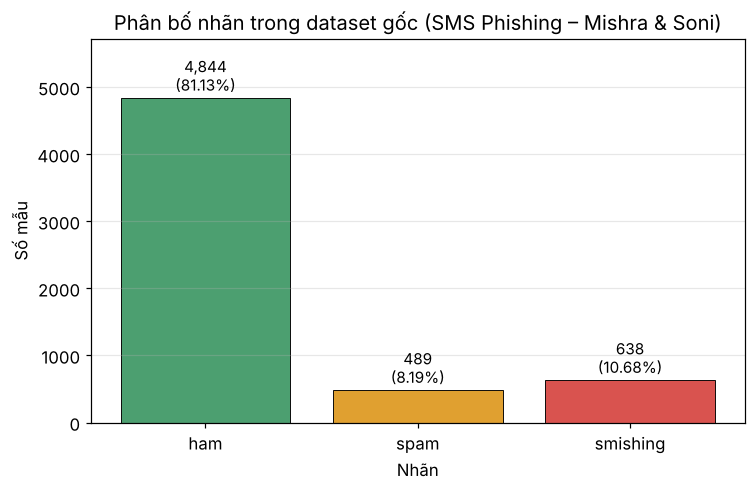

In [11]:
colors = {"ham": "#4C9F70", "spam": "#E0A030", "smishing": "#D9534F"}
bar_colors = [colors.get(l, "#888888") for l in label_counts.index]

fig, ax = plt.subplots(figsize=(7, 4.6))
bars = ax.bar(label_counts.index, label_counts.values, color=bar_colors, edgecolor="black", linewidth=0.6)
for b, n, p in zip(bars, label_counts.values, label_pct.values):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + label_counts.max()*0.01,
            f"{n:,}\n({p:.2f}%)", ha="center", va="bottom", fontsize=10)
ax.set_title("Phân bố nhãn trong dataset gốc (SMS Phishing – Mishra & Soni)")
ax.set_xlabel("Nhãn")
ax.set_ylabel("Số mẫu")
ax.set_ylim(0, label_counts.max() * 1.18)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_FIGS / "01_phan_bo_nhan_goc.png", dpi=200)
plt.show()

### Biểu đồ bổ sung (hữu ích cho phần nhận xét & chọn đặc trưng)
* Độ dài tin nhắn theo nhãn.
* Tỷ lệ tin có URL / EMAIL / PHONE theo từng nhãn.

len_chars                 len_words                
                mean median min  max      mean median min  max
label_norm                                                    
ham             70.7   53.0   2  910      14.2   11.0   1  171
spam           133.9  143.0  18  379      23.0   24.0   2   61
smishing       139.6  146.0  34  383      22.8   24.0   5   68

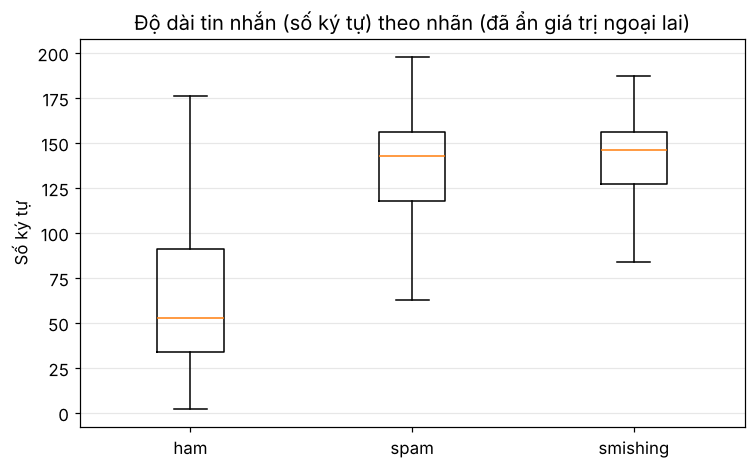

In [12]:
df["len_chars"] = df["TEXT"].str.len()
df["len_words"] = df["TEXT"].str.split().str.len()

len_stats = (df.groupby("label_norm")[["len_chars", "len_words"]]
               .agg(["mean", "median", "min", "max"]).round(1)
               .reindex([l for l in order if l in df["label_norm"].unique()]))
display(len_stats)

fig, ax = plt.subplots(figsize=(7, 4.4))
data = [df.loc[df["label_norm"] == l, "len_chars"] for l in label_counts.index]
ax.boxplot(data, showfliers=False)
ax.set_xticks(range(1, len(label_counts) + 1))
ax.set_xticklabels(list(label_counts.index))
ax.set_title("Độ dài tin nhắn (số ký tự) theo nhãn (đã ẩn giá trị ngoại lai)")
ax.set_ylabel("Số ký tự")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_FIGS / "02_do_dai_tin_nhan_theo_nhan.png", dpi=200)
plt.show()

Cột cờ,EMAIL,PHONE,URL
label_norm,,,
ham,0.02,0.14,0.17
spam,1.43,63.39,20.25
smishing,1.72,82.60,15.67


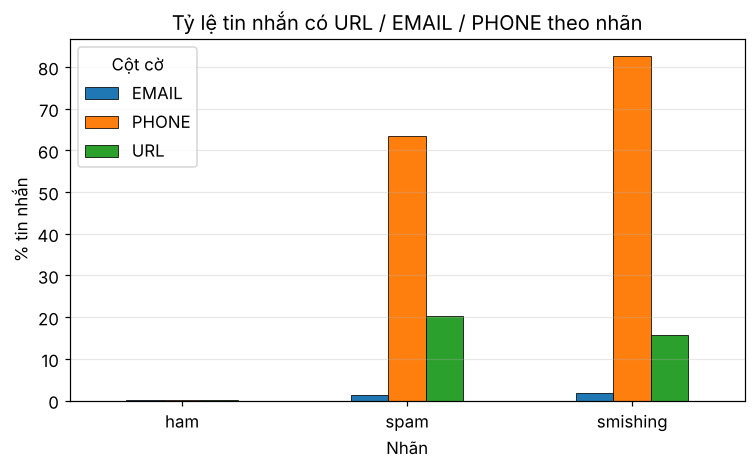

In [13]:
flag_rows = []
for c in FLAG_COLS:
    v = df_raw[c].str.strip().str.lower().eq("yes")
    rate = v.groupby(df["label_norm"]).mean().mul(100).round(2)
    for lab in label_counts.index:
        flag_rows.append((c, lab, rate.get(lab, np.nan)))
flag_df = pd.DataFrame(flag_rows, columns=["Cột cờ", "Nhãn", "% tin có giá trị yes"])
flag_pivot = flag_df.pivot(index="Nhãn", columns="Cột cờ", values="% tin có giá trị yes").reindex(label_counts.index)
display(flag_pivot)

ax = flag_pivot.plot(kind="bar", figsize=(7, 4.4), edgecolor="black", linewidth=0.5)
ax.set_title("Tỷ lệ tin nhắn có URL / EMAIL / PHONE theo nhãn")
ax.set_ylabel("% tin nhắn")
ax.set_xlabel("Nhãn")
plt.xticks(rotation=0)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_FIGS / "03_ti_le_url_email_phone_theo_nhan.png", dpi=200)
plt.show()

## Bước 6. Nhận xét: dữ liệu cân bằng hay mất cân bằng?

**Cách đánh giá (quy ước dùng trong báo cáo):**
* **Tỷ lệ mất cân bằng** = số mẫu nhãn nhiều nhất ÷ số mẫu nhãn ít nhất.
  * < 1,5 → khá cân bằng; 1,5 – 3 → hơi lệch; **> 3 → mất cân bằng rõ rệt**.
* **Baseline “đoán bừa theo lớp đa số”** = % của nhãn lớn nhất. Nếu mô hình chỉ đạt độ chính xác (accuracy) xấp xỉ con số này thì mô hình **chưa học được gì**.

Ô code dưới đây tự tính và in nhận xét theo số liệu thật.

In [14]:
major, minor = label_counts.idxmax(), label_counts.idxmin()
ratio = label_counts.max() / label_counts.min()
baseline = label_pct.max()

if ratio < 1.5:   level = "KHÁ CÂN BẰNG"
elif ratio <= 3:  level = "HƠI LỆCH"
else:             level = "MẤT CÂN BẰNG RÕ RỆT"

print(f"Nhãn nhiều nhất : {major} ({label_counts.max():,} mẫu, {label_pct.max():.2f}%)")
print(f"Nhãn ít nhất    : {minor} ({label_counts.min():,} mẫu, {label_pct.min():.2f}%)")
print(f"Tỷ lệ mất cân bằng (lớn nhất / nhỏ nhất) = {ratio:.1f} : 1")
print(f"Baseline accuracy nếu luôn đoán '{major}'  = {baseline:.2f}%")
print(f"=> Kết luận: dữ liệu {level}.")

# tỷ lệ riêng giữa 2 lớp 'xấu' để thấy sự khác biệt spam vs smishing
if {"spam", "smishing"}.issubset(label_counts.index):
    print(f"Giữa 2 lớp xấu: spam {label_counts['spam']:,} vs smishing {label_counts['smishing']:,} "
          f"(chênh {abs(label_counts['spam']-label_counts['smishing'])/label_counts[['spam','smishing']].min()*100:.1f}%)")

Nhãn nhiều nhất : ham (4,844 mẫu, 81.13%)
Nhãn ít nhất    : spam (489 mẫu, 8.19%)
Tỷ lệ mất cân bằng (lớn nhất / nhỏ nhất) = 9.9 : 1
Baseline accuracy nếu luôn đoán 'ham'  = 81.13%
=> Kết luận: dữ liệu MẤT CÂN BẰNG RÕ RỆT.
Giữa 2 lớp xấu: spam 489 vs smishing 638 (chênh 30.5%)


### Mẫu đoạn nhận xét đưa vào báo cáo
*(Sau khi chạy, thay các chỗ `[...]` bằng số in ra ở ô trên. Với số liệu đã xác minh ở Phần 2, nhãn ham ≈ 81%, spam ≈ 8,2%, smishing ≈ 10,7% → thuộc nhóm “mất cân bằng rõ rệt”.)*

> Dataset gồm **[5.971]** tin nhắn, **[5]** cột. Nhãn **ham** chiếm **[81,1%]**, trong khi **spam** chỉ **[8,2%]** và **smishing** **[10,7%]**. Tỷ lệ giữa nhãn lớn nhất và nhỏ nhất là khoảng **[9,9 : 1]**, do đó dữ liệu **mất cân bằng rõ rệt**. Hai lớp spam và smishing có kích thước tương đương nhau nhưng đều nhỏ hơn nhiều so với ham.
>
> **Hệ quả:** (1) chỉ dùng *accuracy* sẽ gây ảo tưởng, vì mô hình đoán toàn bộ là ham đã đạt ≈ [81%]; (2) cần báo cáo thêm **Precision, Recall, F1 theo từng lớp (macro-F1)** và ma trận nhầm lẫn; (3) khi chia train/test **bắt buộc dùng `stratify`** để giữ nguyên tỷ lệ nhãn ở cả hai tập; (4) có thể cân nhắc `class_prior` hoặc `ComplementNB` trong bước huấn luyện.
>
> **Lưu ý riêng của dataset:** 34 nội dung bị gán đồng thời spam và smishing cho thấy ranh giới 2 nhãn này **không rõ ràng**, cần xử lý ở bước tiền xử lý.

## Bước 7. Lưu các bảng thống kê (sản phẩm bàn giao)
Tất cả ghi ra `outputs/tables/` dưới dạng CSV (mã hóa `utf-8-sig` để **mở bằng Excel không lỗi tiếng Việt**).

In [15]:
overview = pd.DataFrame({
    "Chỉ số": ["Số dòng dữ liệu", "Số cột", "Tên các cột", "Encoding đọc được", "Số giá trị nhãn khác nhau (chưa chuẩn hóa)"],
    "Giá trị": [n_rows, n_cols, ", ".join(df_raw.columns), used_encoding, label_raw_counts.shape[0]],
})

overview.to_csv(OUT_TABLES / "01_tong_quan_dataset.csv", index=False, encoding="utf-8-sig")
label_table.to_csv(OUT_TABLES / "02_phan_bo_nhan.csv", index=False, encoding="utf-8-sig")
label_raw_counts.rename_axis("LABEL (nguyên bản)").reset_index(name="Số mẫu") \
    .to_csv(OUT_TABLES / "03_nhan_nguyen_ban.csv", index=False, encoding="utf-8-sig")
quality_df.to_csv(OUT_TABLES / "04_kiem_tra_chat_luong.csv", index=False, encoding="utf-8-sig")
cmp_df.to_csv(OUT_TABLES / "05_doi_chieu_voi_phan_2.csv", index=False, encoding="utf-8-sig")
flag_pivot.reset_index().to_csv(OUT_TABLES / "06_ti_le_url_email_phone_theo_nhan.csv", index=False, encoding="utf-8-sig")
len_stats.to_csv(OUT_TABLES / "07_do_dai_tin_nhan_theo_nhan.csv", encoding="utf-8-sig")

print("Đã lưu:", *sorted(p.name for p in OUT_TABLES.glob("0[1-7]_*.csv")), sep="\n - ")
print("Biểu đồ:", *sorted(p.name for p in OUT_FIGS.glob("0[1-3]_*.png")), sep="\n - ")

Đã lưu:
 - 01_tong_quan_dataset.csv
 - 02_phan_bo_nhan.csv
 - 03_nhan_nguyen_ban.csv
 - 04_kiem_tra_chat_luong.csv
 - 05_doi_chieu_voi_phan_2.csv
 - 06_ti_le_url_email_phone_theo_nhan.csv
 - 07_do_dai_tin_nhan_theo_nhan.csv
Biểu đồ:
 - 01_phan_bo_nhan_goc.png
 - 02_do_dai_tin_nhan_theo_nhan.png
 - 03_ti_le_url_email_phone_theo_nhan.png
